# Policy result loader

This notebook opens an existing policy result store, dispatches to the policy-specific formatter, and inspects the returned `xarray.Dataset`. Use the dropdown below to select a `.zarr` store under `artifacts/`, ordered by newest first.


In [1]:
import json
import sys
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.colors import TwoSlopeNorm

project_root = Path.cwd()
if not (project_root / "tasks").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    import scienceplots  # noqa: F401
except ModuleNotFoundError:
    scienceplots = None
else:
    plt.style.use("science")
from tasks.policies import load_policy_results
from network_creation.plotting.plot_pair import plot_pair
from network_creation.stats.topology_welfare import normalized_welfare_per_topology
from matplotlib.colors import Normalize
import numpy as np
from scipy.optimize import curve_fit

project_root

PosixPath('/home/hdahmou/Network_creation')

In [2]:
def get_welfare_reference(benefit_to_cost_ratio, distance_discount, n):
    reference_welfare_func = lambda topology_class: normalized_welfare_per_topology(
        topology_class=topology_class,
        n=n,
        benefit_to_cost_ratio=benefit_to_cost_ratio,
        distance_discount=distance_discount,
    )
    reference_welfare_max = reference_welfare_func("max")
    reference_welfare = {
        "star": float(reference_welfare_func("star") / reference_welfare_max),
        "empty": float(reference_welfare_func("empty") / reference_welfare_max),
        "random": float(reference_welfare_func("random") / reference_welfare_max),
    }
    return reference_welfare

In [3]:
def estimate_k_and_plateau(values_timeseries: np.ndarray):
    def exp_rise_from_zero(t, A, k):
        return A * (1 - np.exp(-k * t))

    N, nt = values_timeseries.shape
    t = np.arange(nt, dtype=float)
    A_vals = np.full(N, np.nan)
    k_vals = np.full(N, np.nan)

    for i in range(N):
        y = values_timeseries[i]
        finite = np.isfinite(y)
        if finite.sum() < 3:
            continue
        x = t[finite]
        yy = y[finite]
        A0 = np.nanmax(yy)
        k0 = 0.1
        popt, _ = curve_fit(
            exp_rise_from_zero,
            x,
            yy,
            p0=[A0, k0],
            bounds=([-np.inf, 0], [1, np.inf]),
            maxfev=10000,
        )
        A_vals[i], k_vals[i] = popt

    return A_vals, k_vals

In [4]:
rng = np.random.default_rng(42)

## Load and transform policy results


In [5]:
result_store_candidates = sorted(
    project_root.glob("artifacts/**/*.zarr"),
    key=lambda path: path.stat().st_mtime,
    reverse=True,
)
if not result_store_candidates:
    raise FileNotFoundError("No .zarr result stores found under artifacts/")

result_store_selector = widgets.Dropdown(
    options=[str(path.relative_to(project_root)) for path in result_store_candidates],
    value=str(result_store_candidates[0].relative_to(project_root)),
    description="Result:",
    layout=widgets.Layout(width="95%"),
)
display(result_store_selector)

Dropdown(description='Result:', layout=Layout(width='95%'), options=('artifacts/run-20260428T205524.zarr',), v…

In [7]:
result_store_path = project_root / result_store_selector.value

ds = load_policy_results(result_store_path)
config = json.loads(Path(ds.attrs["config_path"]).read_text(encoding="utf-8"))

{
    "result_store_path": ds.attrs["result_store_path"],
    "config_path": ds.attrs["config_path"],
    "sizes": dict(ds.sizes),
    "data_vars": {name: value.shape for name, value in ds.data_vars.items()},
    "coords": {name: len(value) for name, value in ds.coords.items()},
}


{'result_store_path': '/home/hdahmou/Network_creation/artifacts/run-20260428T205524.zarr',
 'config_path': '/home/hdahmou/Network_creation/artifacts/run-20260428T205524.run_config.json',
 'sizes': {'sample': 8192, 'theta_parameter': 8, 'step': 101, 'observable': 4},
 'data_vars': {'theta': (8192, 8),
  'prior_low': (8,),
  'prior_high': (8,),
  'x': (8192, 101, 4),
  'duration_ms': (8192,)},
 'coords': {'sample': 8192,
  'input_index': 8192,
  'parameter_row': 8192,
  'theta_parameter': 8,
  'observable': 4,
  'policy_proportion_index': 8192,
  'step': 101}}

In [11]:
{
    "data_var_dims": {name: value.dims for name, value in ds.data_vars.items()},
    "coord_names": tuple(ds.coords),
    "attrs": {
        name: ds.attrs[name]
        for name in (
            "average_completion_duration_ms",
        )
    },
}


{'data_var_dims': {'theta': ('sample', 'theta_parameter'),
  'prior_low': ('theta_parameter',),
  'prior_high': ('theta_parameter',),
  'x': ('sample', 'step', 'observable'),
  'duration_ms': ('sample',)},
 'coord_names': ('sample',
  'input_index',
  'parameter_row',
  'theta_parameter',
  'observable',
  'policy_proportion_index',
  'step'),
 'attrs': {'average_completion_duration_ms': 106804.75872523492}}

In [12]:
duration_ms = ds["duration_ms"].values

{
    "sample_count": int(ds.sizes["sample"]),
    "has_failures": bool(ds.attrs.get("has_failures", False)),
    "n_agents": sorted(int(v) for v in np.unique(ds["theta"].sel(theta_parameter="n_agents").values)),
    "average_duration_ms": float(np.nanmean(duration_ms)) if duration_ms.size else None,
}

{'sample_count': 8192,
 'has_failures': False,
 'n_agents': [10],
 'average_duration_ms': 106804.75872523495}

## Plot per-step outputs


In [13]:
timeseries = ds["x"]
final = timeseries.isel(step=-1)
observables = tuple(ds.coords["observable"].values)
steps = ds.coords["step"].values
n_agents_by_sample = ds["theta"].sel(theta_parameter="n_agents").values
n_agents_values = np.unique(n_agents_by_sample)
parameter_rows = ds.coords["parameter_row"].values

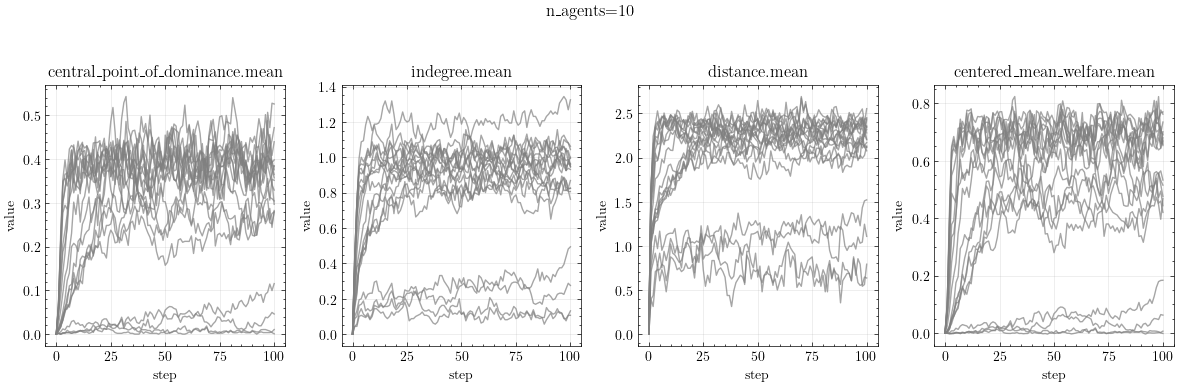

In [14]:
for selected_n_agents in n_agents_values:
    sample_indices = np.flatnonzero(n_agents_by_sample == selected_n_agents)
    if sample_indices.size == 0:
        continue

    fig, axes = plt.subplots(1, len(observables), figsize=(12, 4), sharex=True)
    axes = np.atleast_1d(axes)

    selected_timeseries = timeseries.isel(sample=sample_indices)
    n_subset = min(20, sample_indices.size)
    chosen_positions = rng.choice(sample_indices.size, size=n_subset, replace=False)

    for observable_index, observable_name in enumerate(observables):
        series = selected_timeseries.sel(observable=observable_name)
        for sample_position in chosen_positions:
            parameter_row = int(selected_timeseries.coords["parameter_row"].values[sample_position])
            axes[observable_index].plot(
                steps,
                series.isel(sample=sample_position).values,
                alpha=0.7,
                label=f"row={parameter_row}",
                c="gray",
            )

        axes[observable_index].set_title(str(observable_name))
        axes[observable_index].set_xlabel("step")
        axes[observable_index].set_ylabel("value")
        axes[observable_index].grid(alpha=0.3)

    fig.suptitle(f"n_agents={int(selected_n_agents)}")
    handles, labels = axes[0].get_legend_handles_labels()
    plt.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()

## Pair plots


In [15]:
theta_all = ds["theta"].values
final_all = ds["x"].isel(step=-1).values
theta_labels = tuple(ds.coords["theta_parameter"].values)
observable_labels = tuple(ds.coords["observable"].values)
n_agents = ds["theta"].sel(theta_parameter="n_agents").values
n_agents_values = np.unique(n_agents)

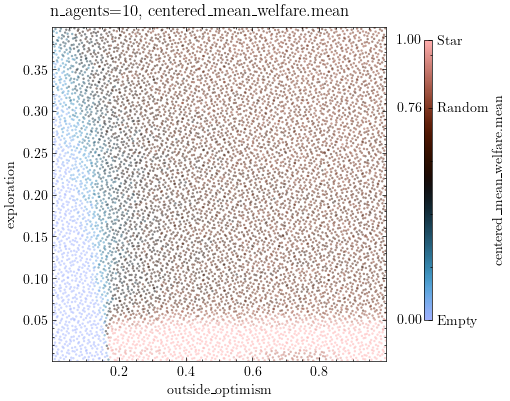

In [16]:
target_idx = -1

for selected_n_agents in n_agents_values:
    mask = n_agents == selected_n_agents
    theta = theta_all[mask]
    final = final_all[mask]
    target_values = final[:, target_idx]
    
    benefit_to_cost_ratio = np.unique(
        theta[:, theta_labels.index("benefit_to_cost_ratio")]
    ).item()
    distance_discount = np.unique(
        theta[:, theta_labels.index("distance_discount")]
    ).item()

    reference_welfare = get_welfare_reference(
        benefit_to_cost_ratio=benefit_to_cost_ratio,
        distance_discount=distance_discount,
        n=int(selected_n_agents),
    )
    
    target_norm = TwoSlopeNorm(
        vmin=reference_welfare["empty"],
        vcenter=reference_welfare["random"],
        vmax=reference_welfare["star"],
    )
    
    fig, axes = plot_pair(
        X=theta,
        y=target_values,
        labels=theta_labels,
        label_y=observable_labels[target_idx],
        atol=1e-5,
        base_fig_size=4.0,
        cmap="berlin",
        method="points",
        resolution=100,
        sigma=2.5,
        #norm=target_norm,
        norm=Normalize(vmin=0.0, vmax=1.0),
        point_size=3,
        ordered_discrete_keys=["visibility_distance"]
    )
    
    cbar_ax = fig.axes[-1]
    vals = [
        reference_welfare["empty"],
        reference_welfare["random"],
        reference_welfare["star"],
    ]
    cbar_ax.set_yticks(vals, labels=["Empty", "Random", "Star"])
    cbar_ax.tick_params(labelright=True, labelleft=False)
    pos = cbar_ax.get_position()
    cbar_ax.set_position([pos.x0 + 0.04, pos.y0, pos.width, pos.height])
    # cbar_ax.yaxis.tick_right()
    for v in vals:
        cbar_ax.text(
            -0.35,
            v,
            f"{v:.2f}",
            transform=cbar_ax.get_yaxis_transform(),
            ha="right",
            va="center",
        )
    
    fig.suptitle(f"n_agents={int(selected_n_agents)}, {observable_labels[target_idx]}")

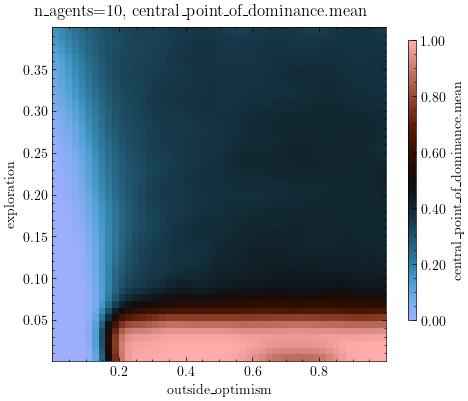

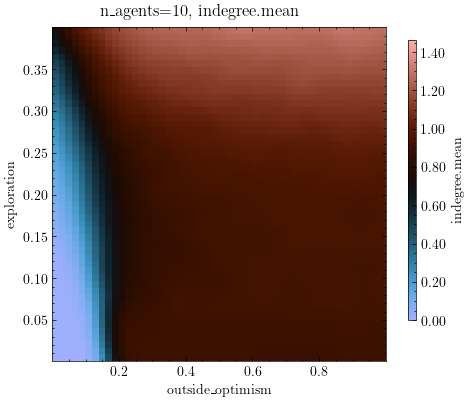

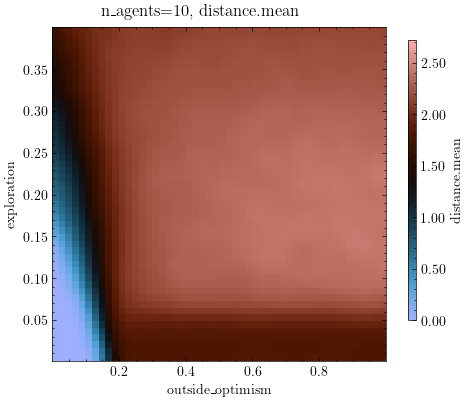

In [17]:
for target_idx in range(len(observable_labels) - 1):
    for selected_n_agents in n_agents_values:
        mask = n_agents == selected_n_agents
        theta = theta_all[mask]
        final = final_all[mask]
        target_values = final[:, target_idx]
        fig, axes = plot_pair(
            X=theta,
            y=target_values,
            labels=theta_labels,
            label_y=observable_labels[target_idx],
            atol=1e-5,
            base_fig_size=4.0,
            cmap="berlin",
            method="gaussian",
            resolution=50,
            # sigma=0.1,
            point_size=3,
            ordered_discrete_keys=["visibility_distance"]
        )
        fig.suptitle(f"n_agents={int(selected_n_agents)}, {observable_labels[target_idx]}")

# Convergence speed

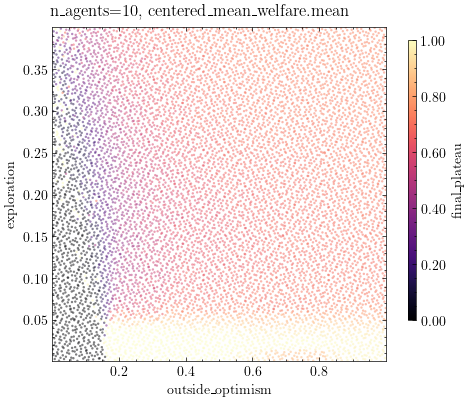

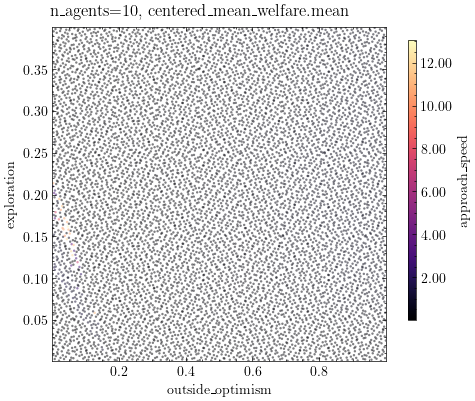

In [18]:
target_idx = -1
for selected_n_agents in n_agents_values:
    mask = n_agents == selected_n_agents
    theta = theta_all[mask]
    selected_timeseries = (
        ds["x"]
        .sel(observable=observable_labels[target_idx])
        .values[mask]
    )

    final_plateau, approach_speed = estimate_k_and_plateau(values_timeseries=selected_timeseries)

    for y, target_label in zip((final_plateau, approach_speed), ("final_plateau", "approach_speed")):
        fig, axes = plot_pair(
            X=theta,
            y=y,
            labels=theta_labels,
            label_y=target_label,
            atol=1e-5,
            base_fig_size=4.0,
            cmap="magma",
            method="points",
            resolution=100,
            #sigma=2.5,
            point_size=3,
            norm=Normalize(vmin=0.0, vmax=1.0) if target_label == "final_plateau" else None,
            ordered_discrete_keys=["visibility_distance"]
        )
        fig.suptitle(f"n_agents={int(selected_n_agents)}, {observable_labels[target_idx]}")